# Part B

## Setup

In [ ]:
import numpy as np
from skimage.feature import corner_harris, peak_local_max, gaussian_filter
import matplotlib.pyplot as plt

## B.1 Harris Corner Detection

In [15]:
def get_harris_corners(im, edge_discard=20):
    """
    This function takes a b&w image and an optional amount to discard
    on the edge (default is 20 pixels), and finds all harris corners
    in the image. Harris corners near the edge are discarded and the
    coordinates of the remaining corners are returned. A 2d array (h)
    containing the h value of every pixel is also returned.

    h is the same shape as the original image, im.
    coords is 2 x n (ys, xs).
    """

    assert edge_discard >= 20

    # find harris corners
    h = corner_harris(im, method='eps', sigma=1)
    coords = peak_local_max(h, min_distance=1)

    # discard points on edge
    edge = edge_discard  # pixels
    mask = (coords[:, 0] > edge) & \
           (coords[:, 0] < im.shape[0] - edge) & \
           (coords[:, 1] > edge) & \
           (coords[:, 1] < im.shape[1] - edge)
    coords = coords[mask].T
    return h, coords


def dist2(x, c):
    """
    dist2  Calculates squared distance between two sets of points.

    Description
    D = DIST2(X, C) takes two matrices of vectors and calculates the
    squared Euclidean distance between them.  Both matrices must be of
    the same column dimension.  If X has M rows and N columns, and C has
    L rows and N columns, then the result has M rows and L columns.  The
    I, Jth entry is the  squared distance from the Ith row of X to the
    Jth row of C.

    Adapted from code by Christopher M Bishop and Ian T Nabney.
    """

    ndata, dimx = x.shape
    ncenters, dimc = c.shape
    assert dimx == dimc, 'Data dimension does not match dimension of centers'

    return (np.ones((ncenters, 1)) * np.sum((x**2).T, axis=0)).T + \
            np.ones((   ndata, 1)) * np.sum((c**2).T, axis=0)    - \
            2 * np.inner(x, c)


def adaptive_non_maximal_suppression(h, coords, max_points=500, c_robust=0.9):
    coords = np.asarray(coords, dtype=int)

    responses = h[coords[0], coords[1]]
    distances = dist2(coords.T, coords.T)

    radii = np.full(len(responses), np.inf)

    for i, response in enumerate(responses):
        stronger = responses > c_robust * response
        stronger[i] = False

        if np.any(stronger):
            radii[i] = np.min(distances[i, stronger])

    selected = np.argsort(radii)[::-1][:max_points]
    return coords[:, selected]

(800, 600) (2, 9389)


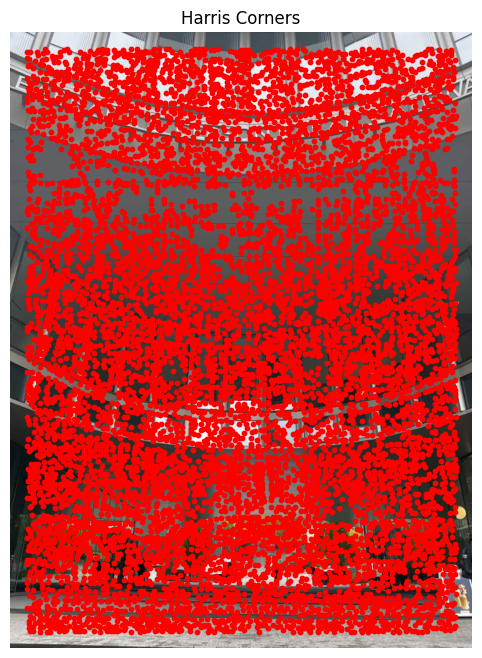

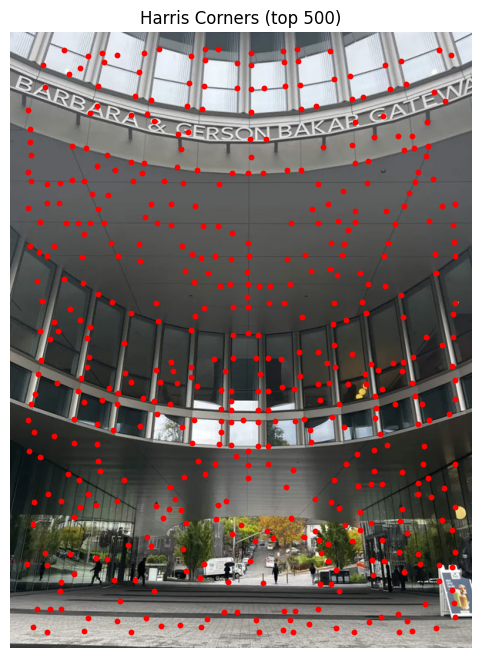

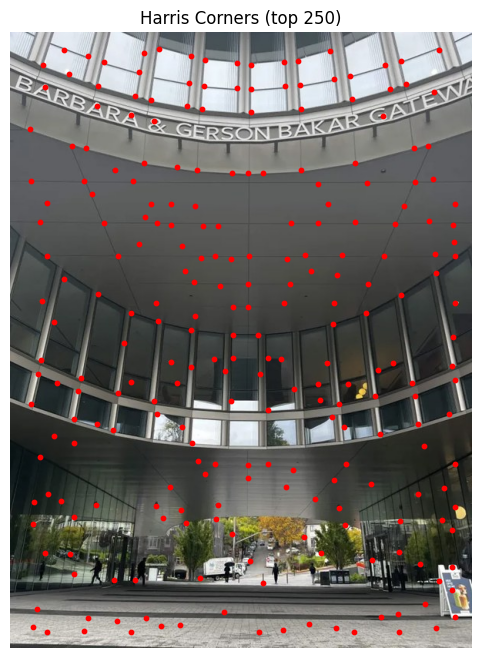

In [28]:
im_gateway_middle = plt.imread("out/src/gateway_middle.jpg")
gray = np.mean(im_gateway_middle[..., :3], axis=2)

h, coords = get_harris_corners(gray)
print(h.shape, coords.shape)

top_500_coords = adaptive_non_maximal_suppression(h, coords, 500)
top_250_coords = adaptive_non_maximal_suppression(h, coords, 250)

plt.figure(figsize=(10, 8))
plt.imshow(im_gateway_middle, cmap="gray")
plt.scatter(coords[1], coords[0], s=10, c="red", marker="o")
plt.axis("off")
plt.title("Harris Corners")
plt.show()

plt.figure(figsize=(10, 8))
plt.imshow(im_gateway_middle, cmap="gray")
plt.scatter(top_500_coords[1], top_500_coords[0], s=10, c="red", marker="o")
plt.axis("off")
plt.title("Harris Corners (top 500)")
plt.show()

plt.figure(figsize=(10, 8))
plt.imshow(im_gateway_middle, cmap="gray")
plt.scatter(top_250_coords[1], top_250_coords[0], s=10, c="red", marker="o")
plt.axis("off")
plt.title("Harris Corners (top 250)")
plt.show()

## B.2 Feature Descriptor Extraction

(500, 64)
(2, 500)


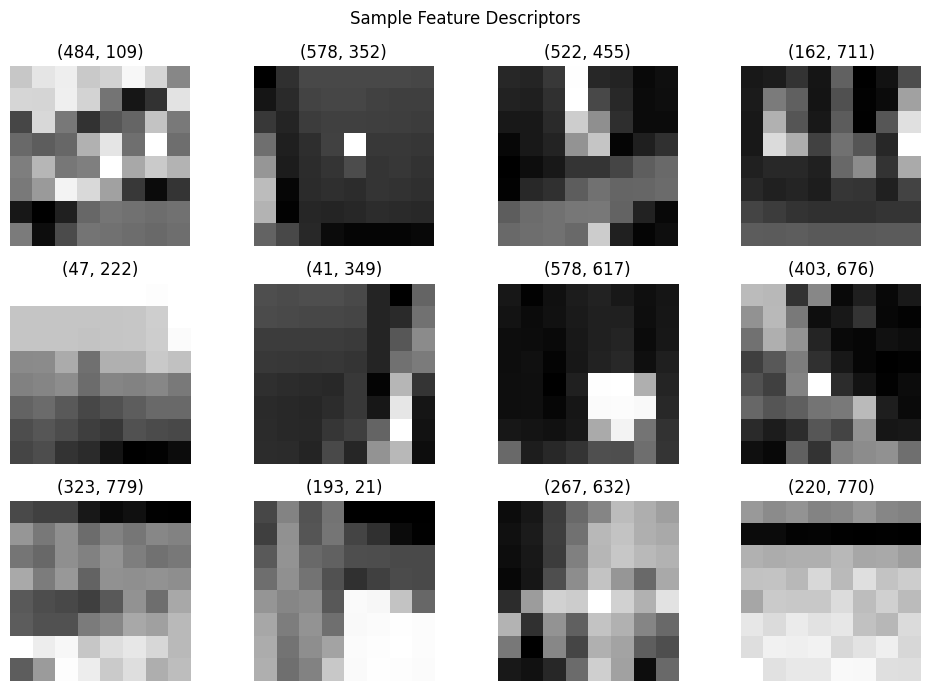

In [32]:
"""
Feature descriptor algorithm
Blur
Sample a 8 × 8 patch of pixels, using a spacing of s = 5 pixels between samples
Normalize
"""

def extract_feature_descriptors(im, coords, spacing=5, patch_size=8, sigma=1):
    blurred = gaussian_filter(im.astype(float), sigma=sigma)

    half = (patch_size - 1) / 2
    offsets = (np.arange(patch_size) - half) * spacing
    dy, dx = np.meshgrid(offsets, offsets, indexing="ij")

    y = coords[0][:, None, None] + dy
    x = coords[1][:, None, None] + dx

    valid = (
        (y.min(axis=(1, 2)) >= 0) &
        (y.max(axis=(1, 2)) < im.shape[0]) &
        (x.min(axis=(1, 2)) >= 0) &
        (x.max(axis=(1, 2)) < im.shape[1])
    )

    y = y[valid]
    x = x[valid]
    valid_coords = coords[:, valid]

    y_int = np.clip(np.round(y).astype(int), 0, im.shape[0] - 1)
    x_int = np.clip(np.round(x).astype(int), 0, im.shape[1] - 1)
    descriptors = blurred[y_int, x_int].reshape(y_int.shape[0], -1) # TODO: review

    descriptors -= descriptors.mean(axis=1, keepdims=True)
    descriptors /= descriptors.std(axis=1, keepdims=True) + 1e-8

    return descriptors, valid_coords


features, feature_coords = extract_feature_descriptors(gray, top_500_coords)

print(features.shape)
print(feature_coords.shape)

n_show = min(12, len(features))
fig, axes = plt.subplots(3, 4, figsize=(10, 7))

for ax, descriptor, (y, x) in zip(
    axes.ravel(), features[:n_show], feature_coords[:, :n_show].T
):
    ax.imshow(descriptor.reshape(8, 8), cmap="gray")
    ax.set_title(f"({x}, {y})")
    ax.axis("off")

for ax in axes.ravel()[n_show:]:
    ax.axis("off")

fig.suptitle("Sample Feature Descriptors")
plt.tight_layout()
plt.show()
